<a href="https://colab.research.google.com/github/zamoralinokevin-eng/Maestria-en-IA/blob/main/Validacion_Evaluacion_Seleccion_271753.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Entrenamiento, ajuste y evaluación de un clasificador tipo Árbol de Decisión
### Maestría en Inteligencia Artificial y Analítica de Datos

**Nombre: Kevin Josue Zamora Lino**

**Matrícula: 271753**

**Ficha técnica**

| | |
|---|---|
| **Modalidad** | Individual |
| **Entorno** | Google Colab |
| **Dataset** | california_housing |
| **Modelo** | Árbol de Decisión |
| **Puntaje total** | 100 puntos |
| **Fecha de entrega** | 2026-11-03 |

##1. Carga de bibliotecas, conjunto de datos y análisis exploratorio de los datos
Declarar las bibliotecas necesarias para este proyecto

Cargar el conjunto de datos Glioma Grading Clinical and Mutation Features. Se puede descargar de https://archive.ics.uci.edu/dataset/759/glioma+grading+clinical+and+mutation+features+dataset

In [39]:
#instalamos ucimlrepo
!pip install ucimlrepo

In [40]:
#Importamos librerías que se usarán el el dataset
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from ucimlrepo import fetch_ucirepo
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, RandomizedSearchCV, GridSearchCV
from sklearn.tree import DecisionTreeClassifier


In [41]:
#se cargan los datos de glioma grading clinical and mutation features
glioma_repo = fetch_ucirepo(id=759)


#se estraen las características y la variable objetivo
X = glioma_repo.data.features
y = glioma_repo.data.targets

#se convierte a una serie la variable objetivo para evitar advertencias
y_series = y.iloc[:,0]

##2. Análisis exploratorio de los datos

1. Describir forma y estructura (shape, describe(), info()).

2. Mostrar la distribución de clases (y.value_counts()).

3. Visualizar:

    Histograma de al menos 3 variables numéricas.

    Boxplots o violin plots por clase si es computacionalmente viable.

    Mapa de calor de correlaciones entre variables.

In [42]:
#se describe la forma y la estructura de los conjuntoa de datos
print("Forma y estructura del dataset")
print(f"Forma de X: {X.shape}")
print(f"Forma de y: {y_series.shape}")

print("\nInformación del dataset de características")
print(X.info())

print("\nDescripción estadística de las características")
print(X.describe())

#se muestra la distribucion de clases de la variable objetivo
print("\nDistribución de clases de la variable objetivo")
print(y_series.value_counts())


Forma y estructura del dataset
Forma de X: (839, 23)
Forma de y: (839,)

Información del dataset de características
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 839 entries, 0 to 838
Data columns (total 23 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Gender            839 non-null    int64  
 1   Age_at_diagnosis  839 non-null    float64
 2   Race              839 non-null    object 
 3   IDH1              839 non-null    int64  
 4   TP53              839 non-null    int64  
 5   ATRX              839 non-null    int64  
 6   PTEN              839 non-null    int64  
 7   EGFR              839 non-null    int64  
 8   CIC               839 non-null    int64  
 9   MUC16             839 non-null    int64  
 10  PIK3CA            839 non-null    int64  
 11  NF1               839 non-null    int64  
 12  PIK3R1            839 non-null    int64  
 13  FUBP1             839 non-null    int64  
 14  RB1               839 

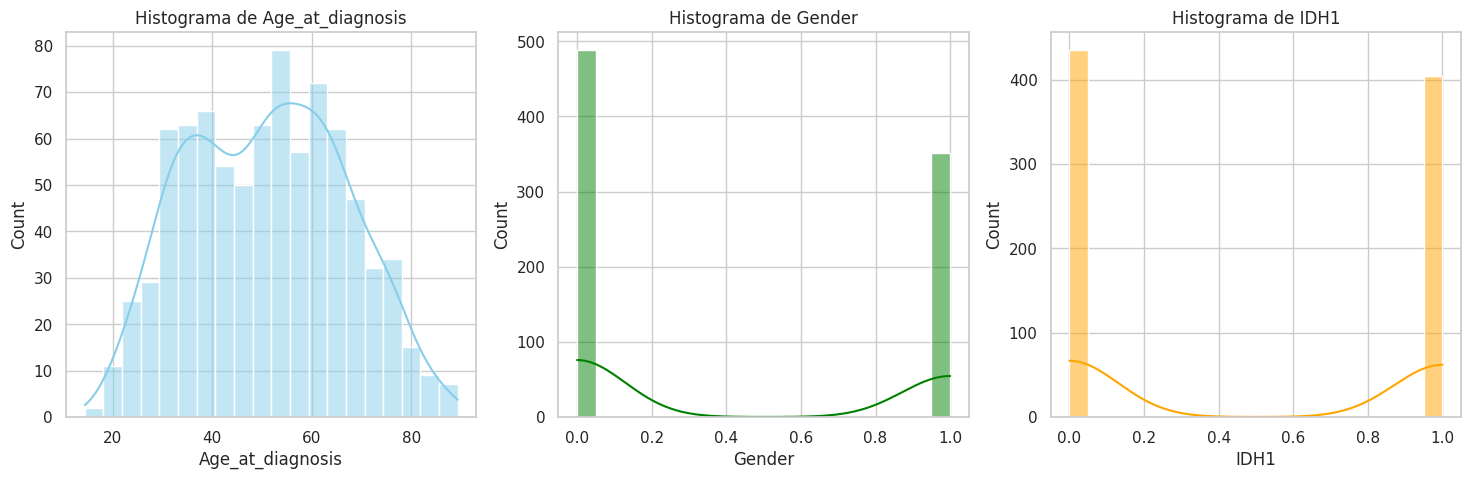

In [43]:
# Visualizar:
# Histograma de al menos 3 variables numéricas.
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1,3,figsize=(18,5))

#las variables numéricas son: Age_at_diagnosis, Gender, Race
#solo Age_at_diagnosis tiene valores variados
#las demás variables numéricas son sólo numeros de 0, 1
sns.histplot(data=X, x="Age_at_diagnosis", bins=20, kde=True, ax=axes[0], color="skyblue")
axes[0].set_title("Histograma de Age_at_diagnosis")

sns.histplot(data=X, x="Gender", bins=20, kde=True, ax=axes[1], color="green")
axes[1].set_title("Histograma de Gender")

sns.histplot(data=X, x="IDH1", bins=20, kde=True, ax=axes[2], color="orange")
axes[2].set_title("Histograma de IDH1")

plt.show()


##Interpretación
Las ultimas dos variables numericas no tiene mucho sentido hacer un histograma porque sólo tienen dos categorías

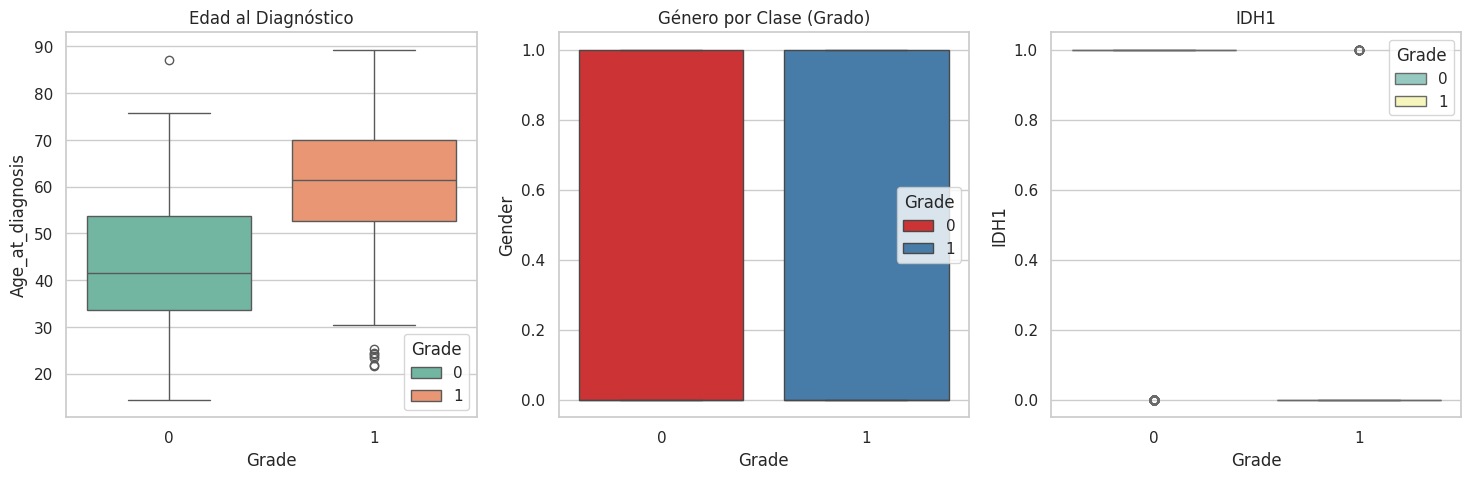

In [44]:
#Boxplots por clase si es computacionalmente viable.
fig, axes = plt.subplots(1,3,figsize=(18,5))
sns.boxplot(x=y_series, y=X['Age_at_diagnosis'], hue=y_series, ax=axes[0], palette='Set2')
axes[0].set_title('Edad al Diagnóstico')

sns.boxplot(x=y_series, y=X['Gender'], hue=y_series, ax=axes[1], palette='Set1')
axes[1].set_title('Género por Clase (Grado)')

sns.boxplot(x=y_series, y=X['IDH1'], hue=y_series, ax=axes[2], palette='Set3')
axes[2].set_title('IDH1')


plt.show()

##Interpretación
Los boxplot tampoco son viables porque las demás variables numéricas sólo presentan 2 categorías, 0 ó 1

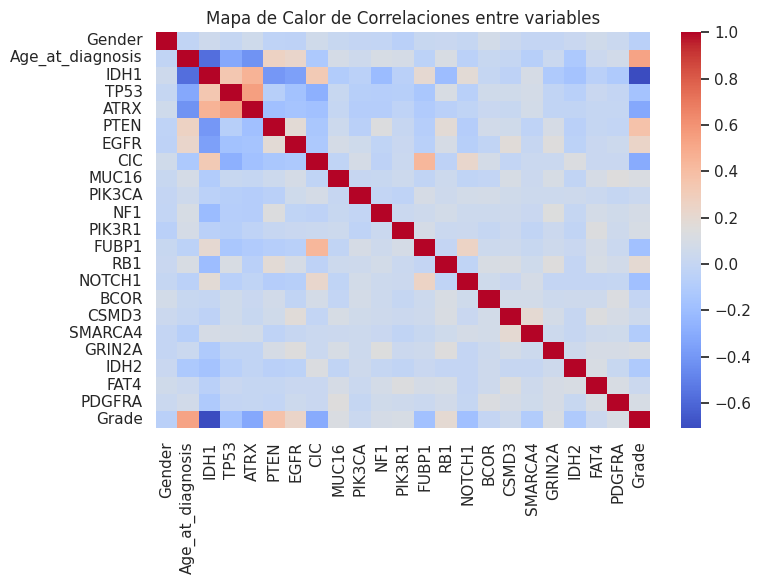

In [45]:
#para graficar el heatmap, eliminamos la variable Race porque tien variables categoricas
#de tipo string y solo queremos variables numéricas
X = X.drop(columns=['Race'], errors='ignore')

# Mapa de calor de correlaciones entre variables.
corr_matrix = pd.concat([X, y], axis=1).corr()

plt.figure(figsize=(8,6))
sns.heatmap(corr_matrix, annot=False, cmap='coolwarm')
plt.title('Mapa de Calor de Correlaciones entre variables')

plt.tight_layout()
plt.show()

##Reflexiona: ¿Existen clases desbalanceadas? ¿Qué atributos parecen más informativos?

Cuando se contaron los valores de la variable objetivo, el 0 que significa glioma de bajo grado, presentó 487 valores. El 1 que significa glioblastoma multiforme, presentó 352 valores. Por lo que se puede decir que si existe un ligero desbalance entre clases en que el 58% representa el valor 0, y el 42% representa el valor 1.

El atributo que parece mas informativo es la edad de diagnóstico porque en el mapa de calor se vió una fuerte correlación con la variable objetivo. La variable IDH1 tiene una correlación muy debil con el grado, esto debido a que su presencia se asocia con gliomas de bajo grado. PTEN tambien trae una relación considerable con el grado del tumor debido a que se marca notoriamente en el mapa de calor. Por otro lado, IDH1 esta relacionado con TP53 y ATRX, esto se explica porque estas mutaciones coinciden con la mutación de IDH1.

##3. Gráfica de errores en entrenamiento y prueba

Entrenar un árbol de decisión con diferentes profundidades.

En la gráfica mostrar las exactitudes en entrenamiento y test, usando un stratified k-fold cross-validation con K= 10

Los valores de las profundides a evaluar son 2, 5, 10, 15, 20, 25, 30 y None

Deberás usar StratifiedKFold con 10 particiones, y un valor aleaotorio de 3

Entrenarás y evaluarás un árbol de decisión con estos distintos valores de profundidades

Usa cross_val_score para entrenar los modelos, usando como métrica de evaluación en scoring ="f1_macro",y el StratifiedKFold, con un valor aleatorio = 7

Muestra una fráfica para los distintos resultados  cuando se usa F1 Macro

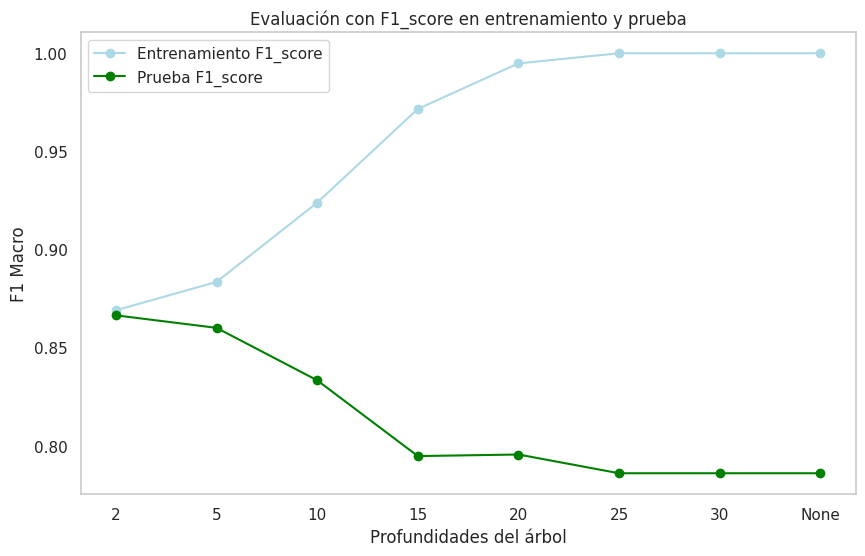

In [46]:
train_scores_mean = []
test_scores_mean = []

#se escriben los valores de las profundidades del árbol
profundidades = [2, 5, 10, 15, 20, 25, 30, None]

#se crea un stratifiedKFold con 10 particionesy valor aleatorio de 3
cv_strat = StratifiedKFold(n_splits=10, shuffle=True, random_state=3)

#se entrena y evalúa el arbol con las diferentes profundidades
for depth in profundidades:
    #se crea un objeto del clasificador con un valor aleatorio de 7
    clf = DecisionTreeClassifier(max_depth=depth, random_state=7)

    #se usa cross_validatepara extraer tanto el score f1_macro
    scores = cross_validate(clf, X, y_series, cv=cv_strat, scoring='f1_macro', return_train_score=True)

    train_scores_mean.append(np.mean(scores['train_score']))
    test_scores_mean.append(np.mean(scores['test_score']))

#se reemplaza el valor None por un string para la visualización en la gráfica
profundidades_labels = [str(d) for d in profundidades]

#se grafica el rendimiento en entrenamiento y prueba con diferentes profundidades del árbol
plt.figure(figsize=(10, 6))
plt.plot(profundidades_labels, train_scores_mean, marker='o', label='Entrenamiento F1_score', color='lightblue')
plt.plot(profundidades_labels, test_scores_mean, marker='o', label='Prueba F1_score', color='green')
plt.xlabel('Profundidades del árbol')
plt.ylabel('F1 Macro')
plt.title('Evaluación con F1_score en entrenamiento y prueba')
plt.legend()
plt.grid(False)
plt.show()



##4. Optimización de hiperparámetros con RandomizedSearchCV

1. Define el espacio de búsqueda aleatorio para los siguientes hiperpárametros:
    Criterion = gini ,entropy
    max_depth: de 5 a 50 con incrementos de 1
    min_samples_split: de 2 a 20 con incrementos de 1

2. Usa el árbol de decisión
StratifiedKfold = 10 (no deberás realizar ninguna partición previa: realiza el ejercicio considerando que es un conjunto de tamaño medio)
n_iter = 5 (combinaciones aleatorias a buscar)
n_jobs = -1 para acelerar cómputo
Métrica de evaluación: f1 Macro
3. Imprime los mejores hiperparámetros encontrados
Imprime el best_score

In [47]:
#se asignan valores a los hiperparámetros criterion, max_depth y min_samples_split
param_dist = {
    'criterion': ['gini', 'entropy'],
    'max_depth': list(range(5, 51)),
    'min_samples_split': list(range(2, 21))
}

cv_tuning = StratifiedKFold(n_splits=10, shuffle=True, random_state=7)

random_search_f1 = RandomizedSearchCV(
    estimator=DecisionTreeClassifier(random_state=7),
    param_distributions=param_dist,
    n_iter=5,     #combinaciones aleatorias a buscar
    scoring='f1_macro', #métrica de evaluación
    cv=cv_tuning,
    n_jobs=-1,    #para acelerar el cómputo
    random_state=7
)

#se entrena el modelo
random_search_f1.fit(X, y_series)

#se imprimen los mejores hiperparámetros y best score
print("\nMétodo seleccionado: RandomizedSearchCV con métrica F1 Macro")
print(f"Mejores hiperparámetros: {random_search_f1.best_params_}")
print(f"Best Score con F1 Macro: {random_search_f1.best_score_:.4f}")




Método seleccionado: RandomizedSearchCV con métrica F1 Macro
Mejores hiperparámetros: {'min_samples_split': 9, 'max_depth': 43, 'criterion': 'entropy'}
Best Score con F1 Macro: 0.8131


##5. Optimización de hiperparámetros con GridSearchCV

Define el espacio de búsqueda  para los siguientes hiperpárametros:
Criterion = gini ,entropy
max_depth: de 5 a 50 con incrementos de 1
min_samples_split: de 2 a 20 con incrementos de 1

Usa el árbol de decisión

StratifiedKfold = 10 (no deberás realizar ninguna partición previa: realiza el ejercicio considerando que es un conjunto de tamaño medio)

Métrica de evaluación: f1 Macro

n_jobs = -1 para acelerar cómputo

Imprime los mejores hiperparámetros encontrados
Imprime el best_score

In [48]:
grid_search_f1 = GridSearchCV(
    estimator=DecisionTreeClassifier(random_state=7),
    param_grid=param_dist,  #el espacio de búsqueda es el mismo que se definió previamente
    scoring='f1_macro', #métrica F1 macro
    cv=cv_tuning,
    n_jobs=-1
)

grid_search_f1.fit(X, y_series)
print("\nMétodo seleccionado: GridSearchCV con métrica F1 Macro")
print(f"Mejores hiperparámetros: {grid_search_f1.best_params_}")
print(f"Best Score con F1 Macro: {grid_search_f1.best_score_:.4f}")



Método seleccionado: GridSearchCV con métrica F1 Macro
Mejores hiperparámetros: {'criterion': 'entropy', 'max_depth': 7, 'min_samples_split': 20}
Best Score con F1 Macro: 0.8638


##6. Optimización de hiperparámetros con RandomizedSearchCV: Accuracy

Define el espacio de búsqueda aleatorio para los siguientes hiperpárametros:

Criterion = gini ,entropy

max_depth: de 5 a 50 con incrementos de 1

min_samples_split: de 2 a 20 con incrementos de 1

Usa el árbol de decisión

StratifiedKfold = 10 (no deberás realizar ninguna partición previa: realiza el ejercicio considerando que es un conjunto de tamaño medio)

n_iter = 5 (combinaciones aleatorias a buscar)

n_jobs = -1 para acelerar cómputo

Métrica de evaluación: accuracy

Imprime los mejores hiperparámetros encontrados

Imprime el best_score


In [49]:
random_search_acc = RandomizedSearchCV(
    estimator=DecisionTreeClassifier(random_state=7),
    param_distributions=param_dist, #los hiperparámetros son los mismos que al proncipio
    n_iter=5,
    scoring='accuracy', #se evalúa el modelo con accuracy
    cv=cv_tuning,
    n_jobs=-1,
    random_state=7
)

#se entrena el modelo
random_search_acc.fit(X, y_series)

#se imprimen resultados
print("\nMétodo seleccionado: RandomizedSearchCV con métrica Accuracy")
print(f"Mejores hiperparámetros: {random_search_acc.best_params_}")
print(f"Best Score con Accuracy: {random_search_acc.best_score_:.4f}")


Método seleccionado: RandomizedSearchCV con métrica Accuracy
Mejores hiperparámetros: {'min_samples_split': 9, 'max_depth': 43, 'criterion': 'entropy'}
Best Score con Accuracy: 0.8188


##7. Optimización de hiperparámetros con GridSearchCV: accuracy

Define el espacio de búsqueda  para los siguientes hiperpárametros:

Criterion = gini ,entropy

max_depth: de 5 a 50 con incrementos de 1

min_samples_split: de 2 a 20 con incrementos de 1

Usa el árbol de decisión

StratifiedKfold = 10 (no deberás realizar ninguna partición previa: realiza el ejercicio considerando que es un conjunto de tamaño medio)

Métrica de evaluación: f1 Macro

n_jobs = -1 para acelerar cómputo

Imprime los mejores hiperparámetros encontrados

Imprime el best_score

In [50]:
grid_search_acc = GridSearchCV(
    estimator=DecisionTreeClassifier(random_state=7),
    param_grid=param_dist,  #los hiperparámetros son los mismos
    scoring='accuracy',
    cv=cv_tuning,
    n_jobs=-1
)

#se entrena el modelo
grid_search_acc.fit(X, y_series)

#se imprimen resultados
print("\nMétodo seleccionado: GridSearchCV con métrica Accuracy")
print(f"Mejores hiperparámetros: {grid_search_acc.best_params_}")
print(f"Best Score con Accuracy: {grid_search_acc.best_score_:.4f}")


Método seleccionado: GridSearchCV con métrica Accuracy
Mejores hiperparámetros: {'criterion': 'entropy', 'max_depth': 7, 'min_samples_split': 20}
Best Score con Accuracy: 0.8653


##8. Actividad de reflexión y análisis

¿Cuál método encontró mejores hiperparámetros?
El método que encontró mejores hiperparámetros fue GridSearchCV ya que este presentó un score >0.86 a diferencia del score de ~0.81 con RandomizedSearchCV. Estos resultados se lograron con profundidades maximas del árbol de 7 a diferencia del otro con profundidades de 43.


¿Cuál fue más costoso computacionalmente?
Debido a que GridSearchCV evalúa todas las combinaciones posibles de los parámetros, tiende a ser el mas costoso. Son 2 combinaciones de criterion x 46 de max_depth x 19 de min_samples_split x 10 folds da un total de 17480 ajustes. En cambio, RandomizedSearchCV solo evalúa una muestra fija aleatoria de n_iter=5.


¿Los resultados en f1_macro set fueron distintos en ambos métodos de optimización? ¿Por qué?
Si fueron distintos en ambos métodos de optimización. En RandomizedSearchCV se obtuvo un F1 score de 0.8131 mientras que en GridSearchCV se obtuvo un valor de 0.8638. Este último tuvo un valor superior porque evaluó todas las combinaciones posibles del grid y el primero sólo tomó muestras aleatorias.


¿Los resultados en accuracy set fueron distintos en ambos métodos de optimización? ¿Por qué?
Si fueron distintos los resultados en Accuracy por la misma razón que GridSearchCV evalúa todo el espacio del grid, obteniendo un valor superior de Accuracy de 0.8653, en comparación con RandomizedSearchCV, que por su carácter aleatorio, tuvo un valor de Accuracy de 0.8188.

¿Los valores de hiperpárametros fueron iguales en Accuracy y F1 Macro ?
En RandomizedSearchCV con metricas Accuracy y F1 score los hiperparámetros fueron los mismos. En GridSearchCV con las métricas de Accuracy y F1 score, los hiperparámetros tambien fueron los mismos. Pero si se compara la misma métrica de rendimiento con los diferentes métodos, si cambian los hiperparámetros. Esto debido a la diferencia del espacio que se explora en ambos métodos. Tambien hay que reforzar que Acuracy busca maximizar la cantidad global de aciertos beneficiando a la clase mayoritaria, mientras que F1 score calcula la media de rendimiento de cada clase penalizando los errores de la clase minoritaria.